## Install and import the required libraries



In [ ]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score 
# train_test_split divides data into train/test. GridSearchCV automates the hyperparameter search. 
# StratifiedKFold creates cross-validation folds that preserve class ratios. cross_val_score runs cross-validation and returns the score for each fold.

from sklearn.preprocessing import StandardScaler
# The tool that rescales features to zero mean / unit variance for SVM.

from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
# The two classifiers themselves. SVC = Support Vector Classifier (the classification version of SVM).

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, roc_auc_score, average_precision_score,
    classification_report, RocCurveDisplay
)
# Every evaluation metric used in Chapter 4: accuracy, precision, recall, F1, the confusion matrix (for FP/FN counts)
# roc_auc_score (ROC-AUC), average_precision_score (PR-AUC), classification_report (prints all of them at once), RocCurveDisplay (plots the ROC curve).

from sklearn.inspection import permutation_importance
# Computes permutation importance — shuffles a feature and measures the performance drop.

from statsmodels.stats.contingency_tables import mcnemar
from scipy import stats
# mcnemar runs McNemar's test directly. scipy.stats supplies ttest_rel, the paired t-test function.

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
# Fixes the random seed everywhere so results are reproducible

print("Libraries loaded.")


Libraries loaded.


In [20]:
LOCAL_CSV_PATH = "PhiUSIIL_Phishing_URL_Dataset.csv"  

import os

if os.path.exists(LOCAL_CSV_PATH):
    df = pd.read_csv(LOCAL_CSV_PATH)
    print(f"Loaded local file: {LOCAL_CSV_PATH}")
else:
    from ucimlrepo import fetch_ucirepo
    phiusiil = fetch_ucirepo(id=967)
    df = pd.concat([phiusiil.data.features, phiusiil.data.targets], axis=1)
    print("Loaded dataset via ucimlrepo.")

print("Shape:", df.shape)
df.head()


Loaded local file: PhiUSIIL_Phishing_URL_Dataset.csv
Shape: (235795, 56)


,FILENAME,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,...,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
0,521848.txt,https://www.southbankmosaics.com,31,www.southbankmosaics.com,24,0,com,100.0,1.000000,0.522907,...,0,0,1,34,20,28,119,0,124,1
1,31372.txt,https://www.uni-mainz.de,23,www.uni-mainz.de,16,0,de,100.0,0.666667,0.032650,...,0,0,1,50,9,8,39,0,217,1
2,597387.txt,https://www.voicefmradio.co.uk,29,www.voicefmradio.co.uk,22,0,uk,100.0,0.866667,0.028555,...,0,0,1,10,2,7,42,2,5,1
3,554095.txt,https://www.sfnmjournal.com,26,www.sfnmjournal.com,19,0,com,100.0,1.000000,0.522907,...,1,1,1,3,27,15,22,1,31,1
4,151578.txt,https://www.rewildingargentina.org,33,www.rewildingargentina.org,26,0,org,100.0,1.000000,0.079963,...,1,0,1,244,15,34,72,1,85,1


## Inspecting the dataset

In [21]:
# Identify the label column (PhiUSIIL uses 'label'; 1 = legitimate, 0 = phishing)
label_col = "label" if "label" in df.columns else df.columns[-1]
print("Label column:", label_col)

print("\nTotal instances:", len(df))
print("\nClass distribution:")
print(df[label_col].value_counts())
print("\nClass distribution (%):")
print((df[label_col].value_counts(normalize=True) * 100).round(2))

print("\nMissing values total:", df.isnull().sum().sum())


Label column: label

Total instances: 235795

Class distribution:
label
1    134850
0    100945
Name: count, dtype: int64

Class distribution (%):
label
1    57.19
0    42.81
Name: proportion, dtype: float64

Missing values total: 0


In [38]:
print("Example legitimate URLs:")
print(df[df[label_col] == 1]["URL"].head(5).to_string(index=False))

print("\nExample phishing URLs:")
print(df[df[label_col] == 0]["URL"].head(5).to_string(index=False))

Example legitimate URLs:
  https://www.southbankmosaics.com
          https://www.uni-mainz.de
    https://www.voicefmradio.co.uk
       https://www.sfnmjournal.com
https://www.rewildingargentina.org

Example phishing URLs:
               http://www.teramill.com
           http://www.f0519141.xsph.ru
              http://www.shprakserf.gq
https://service-mitld.firebaseapp.com/
     http://www.kuradox92.lima-city.de


## Preprocessing: select numeric features
PhiUSIIL includes a few free-text/identifier columns (e.g. `FILENAME`, `URL`, `Domain`, `TLD`, `Title`) that aren't usable directly as numeric model input. This automatically drops any non-numeric columns and keeps everything else as the feature set, matching the content-based feature categories described in Section 3.3.

In [22]:
non_numeric_cols = df.select_dtypes(exclude=[np.number]).columns.tolist()
non_numeric_cols = [c for c in non_numeric_cols if c != label_col]

leakage_cols = ["URLSimilarityIndex"]

print("Dropping non-numeric identifier columns:", non_numeric_cols)
print("Dropping leakage column(s):", leakage_cols)

X = df.drop(columns=non_numeric_cols + leakage_cols + [label_col])
y = df[label_col]

print("\nFinal feature matrix shape:", X.shape)
print("Number of features used:", X.shape[1])


Dropping non-numeric identifier columns: ['FILENAME', 'URL', 'Domain', 'TLD', 'Title']
Dropping leakage column(s): ['URLSimilarityIndex']

Final feature matrix shape: (235795, 49)
Number of features used: 49


## Stratified 80/20 train-test split
Matches Section 3.4: stratified sampling preserves the original class ratio in both partitions.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
# Splits both X and y together into 80% training / 20% test

print("Training set size:", X_train.shape[0])
print("Test set size:", X_test.shape[0])
print("\nTraining class balance:\n", y_train.value_counts(normalize=True).round(4))
print("\nTest class balance:\n", y_test.value_counts(normalize=True).round(4))


Training set size: 188636
Test set size: 47159

Training class balance:
 label
1    0.5719
0    0.4281
Name: proportion, dtype: float64

Test class balance:
 label
1    0.5719
0    0.4281
Name: proportion, dtype: float64


## Cost-sensitive class weighting

Section 3.4 defines the per-class penalty weight as:

**Wj = Nsamples / (Nclasses × Nj)**

This is exactly what scikit-learn computes when you pass `class_weight="balanced"` to `RandomForestClassifier` and `SVC` — so we use the built-in option, which is mathematically identical to the formula above.

In [ ]:
from sklearn.utils.class_weight import compute_class_weight

classes = np.unique(y_train)
# np.unique(y_train) finds the distinct class values

weights = compute_class_weight(class_weight="balanced", classes=classes, y=y_train)
# compute_class_weight calculates the Wj = Nsamples/(Nclasses × Nj) formula automatically for each class.

class_weight_dict = dict(zip(classes, weights))
# zip(classes, weights) pairs each class value with its weight

print("Computed class weights (Wj):", class_weight_dict)


Computed class weights (Wj): {np.int64(0): np.float64(1.1679379860319976), np.int64(1): np.float64(0.8742862439747868)}


## Feature scaling (SVM pipeline only)

Section 3.4: Random Forest is left unscaled (tree splits are scale-invariant). Support Vector Machine requires standardisation. The scaler is fit **only** on the training data and then applied to the test data, to avoid data leakage.

In [ ]:
scaler = StandardScaler()
# StandardScaler() creates a scaler object

X_train_scaled = scaler.fit_transform(X_train)
# fit_transform does two things at once on the training data: fit (learn each feature's mean and standard deviation) and transform (apply the rescaling).

X_test_scaled = scaler.transform(X_test)
# transform on the test data reuses those same learned statistics

print("Scaling complete. SVM will use the scaled versions; Random Forest uses the raw X_train / X_test.")


Scaling complete. SVM will use the scaled versions; Random Forest uses the raw X_train / X_test.


## Hyperparameter optimisation via 5-fold grid search

Matches Table 3.1 exactly:
- **Random Forest**: `n_estimators ∈ {50, 100, 200}`, `max_depth ∈ {10, 20, None}`
- **SVM**: RBF kernel, `C ∈ {0.1, 1.0, 10.0}`, `γ ∈ {'scale', 'auto', 0.01}`

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
# Builds a reusable 5-fold splitting scheme. shuffle=True randomizes row order before splitting

# --- Random Forest grid search ---
rf_param_grid = {
    "n_estimators": [50, 100, 200],
    "max_depth": [10, 20, None],
}
rf_grid = GridSearchCV(
    RandomForestClassifier(class_weight="balanced", random_state=RANDOM_STATE),
    rf_param_grid, cv=cv, scoring="f1", n_jobs=-1
)
rf_grid.fit(X_train, y_train)
# rf_param_grid is a dictionary listing every value to try for each hyperparameter.
# GridSearchCV wraps a fresh, untrained RandomForestClassifier together with that grid, the 5-fold scheme, scoring="f1"
# .fit actually runs the full search: training and validating all 9 combinations across all 5 folds.

print("Best Random Forest params:", rf_grid.best_params_)
print("Best CV F1-score:", round(rf_grid.best_score_, 4))


Best Random Forest params: {'max_depth': None, 'n_estimators': 100}
Best CV F1-score: 0.9999


In [27]:
# --- SVM grid search ---
svm_param_grid = {
    "C": [0.1, 1.0, 10.0],
    "gamma": ["scale", "auto", 0.01],
}
svm_grid = GridSearchCV(
    SVC(kernel="rbf", class_weight="balanced", random_state=RANDOM_STATE),
    svm_param_grid, cv=cv, scoring="f1", n_jobs=-1
)
svm_grid.fit(X_train_scaled, y_train)
print("Best SVM params:", svm_grid.best_params_)
print("Best CV F1-score:", round(svm_grid.best_score_, 4))


Best SVM params: {'C': 10.0, 'gamma': 'auto'}
Best CV F1-score: 0.9997


## Train the final, optimised models and time them
Matches Section 3.6 (Model Training) and the latency figures reported in Table 4.3.

In [ ]:
rf_best = RandomForestClassifier(**rf_grid.best_params_, class_weight="balanced", random_state=RANDOM_STATE)
# rf_grid.best_params_ unpacks directly as keyword arguments into the constructor

t0 = time.time()
rf_best.fit(X_train, y_train)
rf_train_time = time.time() - t0

svm_best = SVC(**svm_grid.best_params_, kernel="rbf", class_weight="balanced",
                probability=True, random_state=RANDOM_STATE)
t0 = time.time()
svm_best.fit(X_train_scaled, y_train)
svm_train_time = time.time() - t0

t0 = time.time()
rf_pred = rf_best.predict(X_test)
# Runs the trained model on the test set and returns its predicted labels.

rf_infer_time = time.time() - t0

t0 = time.time()
svm_pred = svm_best.predict(X_test_scaled)
svm_infer_time = time.time() - t0

print(f"RF  training time: {rf_train_time:.2f}s   |  inference time: {rf_infer_time:.2f}s")
print(f"SVM training time: {svm_train_time:.2f}s   |  inference time: {svm_infer_time:.2f}s")


c:\Users\USER\Documents\SCHOOL\Final Year Project\phishing-env\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


RF  training time: 78.99s   |  inference time: 1.02s
SVM training time: 1146.75s   |  inference time: 16.75s


## Evaluate both models (Section 3.7 / Chapter Four metrics)
Accuracy, precision, recall, F1, false positive rate, ROC-AUC, PR-AUC, and confusion matrix for each classifier.

In [ ]:
def evaluate(name, y_true, y_pred, y_proba):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    fpr = fp / (fp + tn)
# Defines a reusable function. confusion_matrix returns a 2×2 grid of counts; 
# .ravel() flattens it into a flat sequence which is unpacked into the four named counts (true negatives, false positives, false negatives, true positives)

    results = {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1-Score": f1_score(y_true, y_pred),
        "False Positive Rate": fpr,
        "ROC-AUC": roc_auc_score(y_true, y_proba),
        "PR-AUC": average_precision_score(y_true, y_proba),
        "False Positives": fp,
        "False Negatives": fn,
    }
    return results

rf_proba = rf_best.predict_proba(X_test)[:, 1]
svm_proba = svm_best.predict_proba(X_test_scaled)[:, 1]

rf_results = evaluate("Random Forest", y_test, rf_pred, rf_proba)
svm_results = evaluate("SVM", y_test, svm_pred, svm_proba)

results_df = pd.DataFrame([rf_results, svm_results]).set_index("Model")
results_df


,Accuracy,Precision,Recall,F1-Score,False Positive Rate,ROC-AUC,PR-AUC,False Positives,False Negatives
Model,,,,,,,,,
Random Forest,0.999873,0.999815,0.999963,0.999889,0.000248,1.000000,1.000000,5,1
SVM,0.999512,0.999370,0.999778,0.999574,0.000842,0.999995,0.999997,17,6


In [30]:
print("=== Random Forest classification report ===")
print(classification_report(y_test, rf_pred, target_names=["Phishing (0)", "Legitimate (1)"]))

print("=== SVM classification report ===")
print(classification_report(y_test, svm_pred, target_names=["Phishing (0)", "Legitimate (1)"]))


=== Random Forest classification report ===
                precision    recall  f1-score   support

  Phishing (0)       1.00      1.00      1.00     20189
Legitimate (1)       1.00      1.00      1.00     26970

      accuracy                           1.00     47159
     macro avg       1.00      1.00      1.00     47159
  weighted avg       1.00      1.00      1.00     47159

=== SVM classification report ===
                precision    recall  f1-score   support

  Phishing (0)       1.00      1.00      1.00     20189
Legitimate (1)       1.00      1.00      1.00     26970

      accuracy                           1.00     47159
     macro avg       1.00      1.00      1.00     47159
  weighted avg       1.00      1.00      1.00     47159



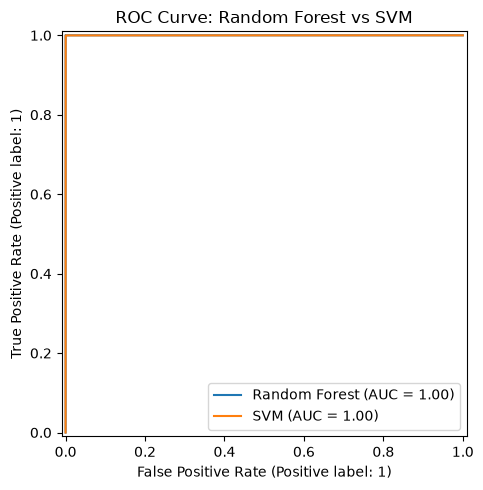

In [37]:
fig, ax = plt.subplots(figsize=(6, 5))
RocCurveDisplay.from_predictions(y_test, rf_proba, name="Random Forest", ax=ax)
RocCurveDisplay.from_predictions(y_test, svm_proba, name="SVM", ax=ax)
ax.set_title("ROC Curve: Random Forest vs SVM")
plt.tight_layout()
plt.show()


## Statistical significance testing (Section 3.7 / Chapter Four, 4.3)

### McNemar's test
Compares the two classifiers on the *same* test instances by looking only at where they disagree.

In [32]:
# Build the 2x2 contingency table of correct/incorrect predictions
rf_correct = (rf_pred == y_test.values)
svm_correct = (svm_pred == y_test.values)

both_correct = np.sum(rf_correct & svm_correct)
rf_only = np.sum(rf_correct & ~svm_correct)   # RF right, SVM wrong
svm_only = np.sum(~rf_correct & svm_correct)  # SVM right, RF wrong
both_wrong = np.sum(~rf_correct & ~svm_correct)

contingency_table = [[both_correct, rf_only],
                      [svm_only, both_wrong]]

print("Contingency table:")
print(pd.DataFrame(contingency_table,
                    index=["SVM correct", "SVM wrong"],
                    columns=["RF correct", "RF wrong"]))

mcnemar_result = mcnemar(contingency_table, exact=False, correction=True)
print(f"\nMcNemar's test: statistic = {mcnemar_result.statistic:.2f}, p-value = {mcnemar_result.pvalue:.4f}")
if mcnemar_result.pvalue < 0.05:
    print("=> Statistically significant difference between the two classifiers (p < 0.05).")
else:
    print("=> No statistically significant difference between the two classifiers (p >= 0.05).")


Contingency table:
             RF correct  RF wrong
SVM correct       47131        22
SVM wrong             5         1

McNemar's test: statistic = 9.48, p-value = 0.0021
=> Statistically significant difference between the two classifiers (p < 0.05).


### 10-fold cross-validated paired t-test and Cohen's d
Cross-validates both models independently across the same 10 folds, then compares the fold-by-fold accuracy scores.

In [33]:
cv10 = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)

rf_cv_scores = cross_val_score(rf_best, X_train, y_train, cv=cv10, scoring="accuracy", n_jobs=-1)
svm_cv_scores = cross_val_score(svm_best, X_train_scaled, y_train, cv=cv10, scoring="accuracy", n_jobs=-1)

print(f"RF  10-fold accuracy: {rf_cv_scores.mean():.4f} +/- {rf_cv_scores.std():.4f}")
print(f"SVM 10-fold accuracy: {svm_cv_scores.mean():.4f} +/- {svm_cv_scores.std():.4f}")

t_stat, p_value = stats.ttest_rel(rf_cv_scores, svm_cv_scores)
print(f"\nPaired t-test: t = {t_stat:.2f}, p = {p_value:.4f}")

diff = rf_cv_scores - svm_cv_scores
cohens_d = diff.mean() / diff.std(ddof=1)
print(f"Cohen's d = {cohens_d:.2f}")


RF  10-fold accuracy: 0.9999 +/- 0.0001
SVM 10-fold accuracy: 0.9997 +/- 0.0001

Paired t-test: t = 4.83, p = 0.0009
Cohen's d = 1.53


## Feature importance (Section 3.7 / Chapter Four, 4.5)
Gini importance from Random Forest, validated with permutation importance on the test set.

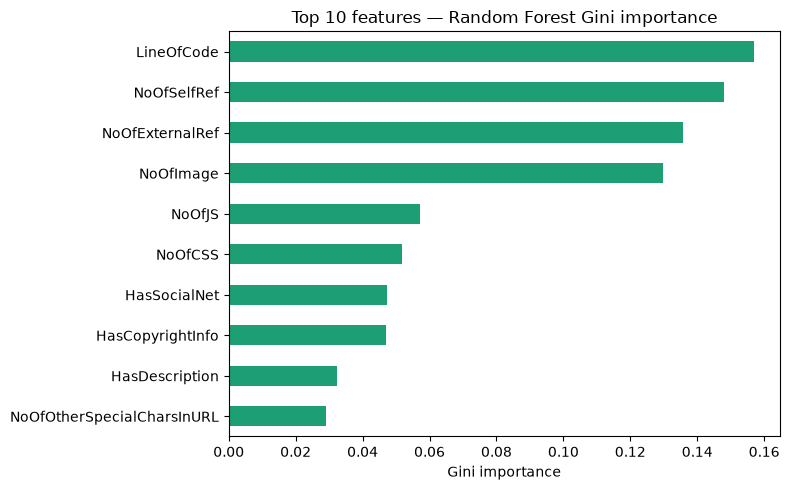

LineOfCode                    0.156883
NoOfSelfRef                   0.147852
NoOfExternalRef               0.135643
NoOfImage                     0.129747
NoOfJS                        0.057261
NoOfCSS                       0.051731
HasSocialNet                  0.047259
HasCopyrightInfo              0.046873
HasDescription                0.032220
NoOfOtherSpecialCharsInURL    0.028970
dtype: float64


In [34]:
gini_importances = pd.Series(rf_best.feature_importances_, index=X.columns).sort_values(ascending=False)
top10_gini = gini_importances.head(10)

fig, ax = plt.subplots(figsize=(8, 5))
top10_gini.sort_values().plot(kind="barh", ax=ax, color="#1D9E75")
ax.set_xlabel("Gini importance")
ax.set_title("Top 10 features — Random Forest Gini importance")
plt.tight_layout()
plt.show()

print(top10_gini)


In [35]:
# Permutation importance (model-agnostic, computed on the test set)
perm_result = permutation_importance(
    rf_best, X_test, y_test, n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1
)
perm_importances = pd.Series(perm_result.importances_mean, index=X.columns).sort_values(ascending=False)
print("Top 10 features by permutation importance:")
print(perm_importances.head(10))


Top 10 features by permutation importance:
IsHTTPS                       0.125166
LineOfCode                    0.050130
NoOfSubDomain                 0.034358
NoOfSelfRef                   0.007135
LetterRatioInURL              0.002358
NoOfImage                     0.000178
NoOfOtherSpecialCharsInURL    0.000159
NoOfExternalRef               0.000068
LargestLineLength             0.000036
HasSocialNet                  0.000034
dtype: float64


## Final summary table

This mirrors Table 4.1 in Chapter Four

In [36]:
summary = results_df.copy()
summary.loc["Random Forest", "Training Time (s)"] = rf_train_time
summary.loc["SVM", "Training Time (s)"] = svm_train_time
summary.loc["Random Forest", "Inference Time (s)"] = rf_infer_time
summary.loc["SVM", "Inference Time (s)"] = svm_infer_time
summary


,Accuracy,Precision,Recall,F1-Score,False Positive Rate,ROC-AUC,PR-AUC,False Positives,False Negatives,Training Time (s),Inference Time (s)
Model,,,,,,,,,,,
Random Forest,0.999873,0.999815,0.999963,0.999889,0.000248,1.000000,1.000000,5,1,78.993181,1.020501
SVM,0.999512,0.999370,0.999778,0.999574,0.000842,0.999995,0.999997,17,6,1146.746830,16.745388
